# 04 Model Selection

**Project:** CreditLens, SME credit risk scoring for guaranteed loans
**CRISP-DM phase:** Modeling (brief stage 5: model selection and development)
**Author:** Mansoor Mohamed Mansoor Saeed Alwahedi

**Purpose.** Notebook 03 gave us a feature table and a fixed train/test split. Here we decide which kind of model CreditLens should use. We first settle two questions about the inputs that notebook 03 left open: which features can be valued for a new application in 2026, and how much the model depends on loan term. We then compare five models of increasing flexibility on identical cross-validation folds of the training split, test whether class weighting helps, and check the chosen model for overfitting. Model selection is based on cross-validation only; the test split is scored for reporting, so the reader can see that the ranking holds on unseen loans.

**Inputs:** `data/processed/loans_features.parquet`, `data/processed/test_ids.parquet` (through `src.modelling.split_data`).

**Outputs:** `docs/model_comparison.csv`, `docs/feature_set_sensitivity.csv`, `docs/class_weight_comparison.csv` and figures `docs/figures/fig04_*.png`. The tuned final model is built in notebook 05.

## 1. Setup

We add the repository root to the path, import the shared modules from `src` and set the plotting style used in every notebook. `src/evaluation.py` holds the cost matrix functions and `src/modelling.py` the preprocessing pipelines, so notebook 05 and the app use exactly the same code.

In [1]:
import sys
import json
import time
import warnings
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from lightgbm import LGBMClassifier
from sklearn.calibration import calibration_curve
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, brier_score_loss, f1_score, precision_recall_curve,
                             precision_score, recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import learning_curve

from src import config
from src import evaluation as ev
from src import features as fe
from src import modelling as md

NOTEBOOK_START = time.time()
# LightGBM and scikit-learn warn that the arrays inside the pipeline have no column names; harmless here
warnings.filterwarnings("ignore", message="X does not have valid feature names")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)

plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 10,
})
P = config.PALETTE
MODEL_COLOURS = {"Dummy (prior)": P["grey"], "Logistic regression": P["amber"], "Random forest": P["teal"],
                 "Hist gradient boosting": P["red"], "LightGBM": P["navy"]}
config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)
N_JOBS = 4  # the machine has 8 threads and 8 GB of memory


def save_fig(fig, name):
    """Save a figure to docs/figures at 150 dpi and print the relative path."""
    path = config.FIGURES_DIR / name
    fig.savefig(path, dpi=150, bbox_inches="tight")
    print(f"Saved {path.relative_to(config.PROJECT_ROOT)}")

## 2. The problem type and how we measure success

CreditLens predicts whether an SME loan will be charged off (`Default = 1`) or repaid (`Default = 0`) from what the bank knows when it decides. This is supervised binary classification, but the bank does not use the yes or no answer directly: it uses the predicted probability of default to rank applications and to compute the expected value of each loan. That shapes the choice of metrics.

* **ROC-AUC** is our primary metric. It is the probability that a randomly chosen defaulted loan gets a higher score than a randomly chosen repaid loan, so it measures ranking quality independently of any threshold. SMART objective 1 asks for at least 0.80.
* **PR-AUC** (average precision) complements it. Only 17.6% of loans default, and ROC-AUC can look good while the model still mixes many repaid loans in among the ones it flags. PR-AUC focuses on the defaulted minority; a model without skill scores the default rate, about 0.18.
* **Recall and precision on defaults at the business threshold.** Recall is the share of defaulted loans the model would decline or refer; SMART objective 1 asks for at least 0.70. The threshold itself is chosen in notebook 05 from the cost matrix; in this notebook we show recall at 0.5 only as a common reference point.
* **Brier score** is the mean squared difference between the predicted probability and the outcome. The expected value of a loan is computed from the probability, so the probabilities must be well calibrated and not just well ordered.
* **Net value from the cost matrix** in `src/config.py`: approving a repaid loan earns 5% of the disbursed amount, approving a loan that defaults loses 50% of the unguaranteed principal plus a 5% workout cost, and declining earns and loses nothing. It is the metric the bank actually cares about and is used to set the threshold in notebook 05.

The cell below shows what the cost matrix implies. Approving a loan is worth it only while its probability of default is below a break-even level that depends on the guaranteed share.

In [2]:
# Cost assumptions shared with notebook 05 and the app
print(f"Net interest margin on a repaid loan: {config.NET_INTEREST_MARGIN:.0%} of the disbursed amount")
print(f"Loss given default: {config.LOSS_GIVEN_DEFAULT:.0%} of the unguaranteed principal")
print(f"Workout cost on default: {config.WORKOUT_COST_RATE:.0%} of the disbursed amount")
print(f"Minimum approval rate: {config.MIN_APPROVAL_RATE:.0%}")

# Break-even probability of default by guaranteed share
breakeven = pd.DataFrame({"guaranteed_share": [0.50, 0.75, 0.85]})
breakeven["breakeven_pd"] = ev.breakeven_probability(breakeven["guaranteed_share"])
breakeven.round(3)

Net interest margin on a repaid loan: 5% of the disbursed amount
Loss given default: 50% of the unguaranteed principal
Workout cost on default: 5% of the disbursed amount
Minimum approval rate: 75%


,guaranteed_share,breakeven_pd
0,0.50,0.143
1,0.75,0.222
2,0.85,0.286


With a 50% guarantee, approving pays only while the probability of default is below 14.3%; with an 85% guarantee the bank can accept up to 28.6%. A model is therefore useful to the bank only if it separates loans well in the low-probability region where these decisions are made, which is another reason to look beyond accuracy.

## 3. Load the feature table and reproduce the split

We reload the feature table from notebook 03 and call `md.split_data()`, which reads the saved test loan numbers, so the 179,191 test loans are exactly the ones notebook 03 set aside. We keep every column in the split frames: the pipelines select their own inputs by name and ignore the rest, and the amounts are needed later for the cost matrix.

In [3]:
df = pd.read_parquet(config.FEATURES_DATA_PATH)
X_train, X_test, y_train, y_test = md.split_data(df, feature_columns=list(df.columns))
print(f"Feature table: {df.shape[0]:,} loans, {df.shape[1]} columns")
print(f"Train: {len(X_train):,} loans, default rate {y_train.mean():.2%}")
print(f"Test:  {len(X_test):,} loans, default rate {y_test.mean():.2%}")
assert len(X_train) == 716_761 and len(X_test) == 179_191

# The identical five folds used for every comparison in this notebook
FOLDS = md.cv_folds(5)
print("Cross-validation:", FOLDS)

Feature table: 895,952 loans, 37 columns
Train: 716,761 loans, default rate 17.56%
Test:  179,191 loans, default rate 17.57%
Cross-validation: StratifiedKFold(n_splits=5, random_state=42, shuffle=True)


## 4. Decision (a): leave the calendar features out of the deployed model

`ApprovalYear`, `ApprovalMonth` and `DisbursementLagDays` were among the most informative features in notebook 03, but they cannot be used by a bank scoring a new application in 2026, for three reasons.

1. **No valid value for a new loan.** The training data covers approvals up to 2014. A 2026 application would have an approval year that the model has never seen, and a tree model treats it like the latest year in the data, which is 2014, a year in which almost no loan had yet had time to fail.
2. **Right-censoring.** Notebook 03 showed that the default rate falls from 44.4% for 2007 approvals to 2.2% for 2013. The fall is mostly an artefact of when the file was extracted: recent loans could only appear as repaid if they had been repaid early. A model that uses the approval year learns this artefact, not credit risk.
3. **Not known at decision time.** The disbursement lag is only known after the loan has been paid out, which is after the credit decision we support.

We therefore remove these three features from the deployed model. We keep `Recession`, because the app lets a credit officer switch it on as a stress scenario (would this loan be safe if it ran through a downturn like 2008?). To make the cost of the decision visible, we score LightGBM with default settings on the same five folds and the same test split with the full feature set of notebook 03 and with the deployment feature set.

In [4]:
def lgbm(**params):
    """LightGBM with default settings except threads, seed and silence."""
    return LGBMClassifier(n_jobs=N_JOBS, random_state=config.RANDOM_STATE, verbose=-1, **params)


def test_scores(y_true, p, threshold=0.5):
    """Test-split ranking and calibration scores, plus threshold metrics at ``threshold``."""
    pred = (p >= threshold).astype(int)
    return {"test_roc_auc": roc_auc_score(y_true, p), "test_pr_auc": average_precision_score(y_true, p),
            "test_brier": brier_score_loss(y_true, p), "test_recall_at_0.5": recall_score(y_true, pred),
            "test_precision_at_0.5": precision_score(y_true, pred, zero_division=0),
            "test_f1_at_0.5": f1_score(y_true, pred)}


def evaluate(name, pipe, X_cv, y_cv, X_fit=None, y_fit=None, cv=FOLDS, train_score=False):
    """Cross-validate ``pipe`` on (X_cv, y_cv), refit on (X_fit, y_fit) and score the test split."""
    X_fit = X_cv if X_fit is None else X_fit
    y_fit = y_cv if y_fit is None else y_fit
    row = {"model": name, "n_cv_rows": len(X_cv)}
    row.update(md.cross_validate_model(pipe, X_cv, y_cv, cv=cv, return_train_score=train_score))
    start = time.time()
    pipe.fit(X_fit, y_fit)
    row["full_fit_seconds"] = time.time() - start
    p = pipe.predict_proba(X_test)[:, 1]
    row.update(test_scores(y_test, p))
    print(f"{name}: CV ROC-AUC {row['cv_roc_auc_mean']:.4f} (sd {row['cv_roc_auc_std']:.4f}), "
          f"CV PR-AUC {row['cv_pr_auc_mean']:.4f}, test ROC-AUC {row['test_roc_auc']:.4f}, "
          f"test PR-AUC {row['test_pr_auc']:.4f}, fit {row['full_fit_seconds']:.1f} s")
    return row, p, pipe


ALL_NUM, CAT = fe.NUMERIC_FEATURES, fe.CATEGORICAL_FEATURES
DEP_NUM = fe.DEPLOYMENT_NUMERIC_FEATURES
print("Removed for deployment:", fe.CALENDAR_FEATURES)
print(f"Deployment feature set: {len(fe.DEPLOYMENT_FEATURES)} input columns")

sensitivity_rows = []
row, _, _ = evaluate("A. Full feature set of notebook 03", md.make_pipeline(lgbm(), ALL_NUM, CAT), X_train, y_train)
row["n_features"] = len(fe.FEATURE_COLUMNS)
sensitivity_rows.append(row)
row, p_lgbm_default, _ = evaluate("B. Deployment feature set", md.make_pipeline(lgbm(), DEP_NUM, CAT), X_train, y_train)
row["n_features"] = len(fe.DEPLOYMENT_FEATURES)
sensitivity_rows.append(row)

Removed for deployment: ['ApprovalYear', 'ApprovalMonth', 'DisbursementLagDays']
Deployment feature set: 23 input columns


A. Full feature set of notebook 03: CV ROC-AUC 0.9801 (sd 0.0005), CV PR-AUC 0.9241, test ROC-AUC 0.9805, test PR-AUC 0.9225, fit 10.7 s


B. Deployment feature set: CV ROC-AUC 0.9748 (sd 0.0006), CV PR-AUC 0.9081, test ROC-AUC 0.9748, test PR-AUC 0.9068, fit 9.1 s


Leaving out the three calendar features costs LightGBM 0.0053 of cross-validated ROC-AUC (0.9801 to 0.9748) and 0.016 of PR-AUC (0.9241 to 0.9081), and the test split shows the same change (ROC-AUC 0.9805 to 0.9748). The price is small because much of what the approval year said about risk is also carried by features that can be valued for a new loan: the guaranteed share tracks the loan programme of each era, and the lender and revolving-credit code track the products of the 2000s. We accept the loss. A model whose second most informative input in notebook 03 has no meaningful value in 2026 would look better on paper and be less reliable in use.

## 5. Decision (b): how much does the model depend on loan term?

Notebook 03 found that `TermYears` carries four times the mutual information of any other feature and that `RealEstate` is derived from it. It also raised the possibility that, for some charged-off loans, the recorded term reflects the shortened life of the loan rather than the term agreed at approval. We run the deployment model again without `TermYears` and `RealEstate` so the reader can see how much of the performance rests on term.

In [5]:
no_term_num = [c for c in DEP_NUM if c not in fe.TERM_FEATURES]
row, p_no_term, _ = evaluate("C. Deployment set without TermYears and RealEstate",
                             md.make_pipeline(lgbm(), no_term_num, CAT), X_train, y_train)
row["n_features"] = len(fe.DEPLOYMENT_FEATURES) - len(fe.TERM_FEATURES)
sensitivity_rows.append(row)

sensitivity = pd.DataFrame(sensitivity_rows)
cols = ["model", "n_features", "cv_roc_auc_mean", "cv_roc_auc_std", "cv_pr_auc_mean", "cv_pr_auc_std",
        "test_roc_auc", "test_pr_auc", "test_brier", "test_recall_at_0.5", "fit_seconds_per_fold"]
sensitivity = sensitivity[cols]
sensitivity.to_csv(config.DOCS_DIR / "feature_set_sensitivity.csv", index=False)
print("Saved docs/feature_set_sensitivity.csv")
sensitivity.round(4)

C. Deployment set without TermYears and RealEstate: CV ROC-AUC 0.8379 (sd 0.0005), CV PR-AUC 0.5799, test ROC-AUC 0.8395, test PR-AUC 0.5850, fit 8.0 s
Saved docs/feature_set_sensitivity.csv


,model,n_features,cv_roc_auc_mean,cv_roc_auc_std,cv_pr_auc_mean,cv_pr_auc_std,test_roc_auc,test_pr_auc,test_brier,test_recall_at_0.5,fit_seconds_per_fold
0,A. Full feature set of notebook 03,26,0.9801,0.0005,0.9241,0.0016,0.9805,0.9225,0.0359,0.8363,7.6101
1,B. Deployment feature set,23,0.9748,0.0006,0.9081,0.0022,0.9748,0.9068,0.0412,0.8074,9.7957
2,C. Deployment set without TermYears and RealEs...,21,0.8379,0.0005,0.5799,0.0020,0.8395,0.5850,0.1048,0.3187,6.4992


The chart puts the three feature sets side by side, with the cross-validation spread shown as error bars.

Saved docs/figures/fig04_feature_set_sensitivity.png


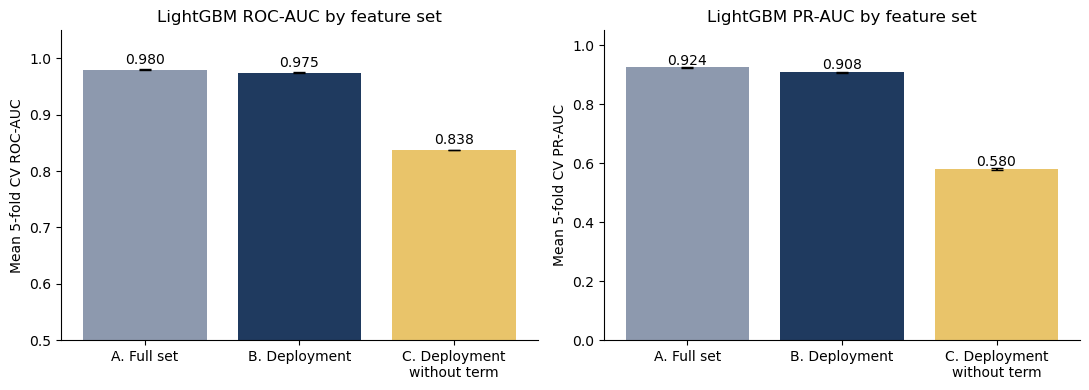

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
labels = ["A. Full set", "B. Deployment", "C. Deployment\nwithout term"]
colours = [P["grey"], P["navy"], P["amber"]]
for ax, metric, title in zip(axes, ["roc_auc", "pr_auc"], ["ROC-AUC", "PR-AUC"]):
    means = sensitivity[f"cv_{metric}_mean"]
    ax.bar(labels, means, yerr=sensitivity[f"cv_{metric}_std"], color=colours, capsize=4)
    for i, v in enumerate(means):
        ax.text(i, v + 0.01, f"{v:.3f}", ha="center")
    ax.set_ylim(0.5 if metric == "roc_auc" else 0.0, 1.05)
    ax.set_ylabel(f"Mean 5-fold CV {title}")
    ax.set_title(f"LightGBM {title} by feature set")
fig.tight_layout()
save_fig(fig, "fig04_feature_set_sensitivity.png")
plt.show()

Without term the model is still well above chance, but it is a much weaker tool: CV ROC-AUC falls from 0.9748 to 0.8379 and PR-AUC from 0.9081 to 0.5799, and on the test split recall on defaults at a threshold of 0.5 drops from 0.81 to 0.32. Most of the model's accuracy therefore rests on loan term.

We keep `TermYears` and `RealEstate` in the final model for three reasons. First, the term is a contractual field agreed and recorded at approval, so it is available when the decision is made, which is the test our leakage rule applies. Second, the direction of the effect has a credit explanation: long terms are typical of real-estate loans secured on property, and very short terms of working-capital loans and revolving lines, which are riskier. Third, the model without term still reaches a ROC-AUC of 0.84, above the 0.80 of SMART objective 1, so the model does not stand or fall with term. The concern raised in notebook 03, that some recorded terms may have been shortened after a loan failed, cannot be tested with this data. We record it as the main limitation in the model card and recommend that a bank adopting CreditLens confirms that its term field holds the term agreed at approval.

## 6. The candidate models

From here on every model uses the deployment feature set: 15 numeric inputs (including the 0/1 indicators), 7 categorical inputs and the lending bank, which `BankEncoder` turns into `BankSize` and an out-of-fold `BankDefaultRate` inside each fold. The logistic regression receives scaled numbers and one-hot categories from `md.build_preprocessor()`. The tree models receive the same information through `md.build_tree_preprocessor()`, which gives each category an integer code instead of a one-hot column, because trees need no scaling and one column per feature keeps them fast and makes the SHAP explanations in notebook 05 map one to one onto features. Neither preprocessor one-hot encodes `Bank`.

Every model is cross-validated on the same five folds of the 716,761 training loans, refitted on the whole training split and then scored once on the test split. The one exception is the random forest, explained in section 6.3.

### 6.1 Dummy classifier (prior)

**How it works.** The dummy classifier ignores the features and predicts the training default rate, 17.6%, for every loan.

**Why we include it.** It sets the floor: any real model must beat it. Its ROC-AUC is 0.5 by construction, its PR-AUC equals the default rate and its Brier score shows the error of knowing only the base rate.

**Strengths and weaknesses.** It costs nothing and cannot overfit, but it cannot tell one loan from another, so as a lending policy it is equivalent to approving everything.

In [7]:
comparison_rows, test_probs, fitted = [], {}, {}

name = "Dummy (prior)"
row, test_probs[name], fitted[name] = evaluate(
    name, md.make_pipeline(DummyClassifier(strategy="prior"), DEP_NUM, CAT), X_train, y_train)
comparison_rows.append(row)

Dummy (prior): CV ROC-AUC 0.5000 (sd 0.0000), CV PR-AUC 0.1756, test ROC-AUC 0.5000, test PR-AUC 0.1757, fit 4.9 s


### 6.2 Logistic regression

**How it works.** Logistic regression adds up the inputs, each multiplied by a learned weight, and passes the total through an S-shaped curve to turn it into a probability. Each weight says how much a feature moves the log-odds of default when the others are held fixed.

**Why it fits a credit problem.** It is the traditional scorecard model in credit risk: regulators and credit committees know it, and every coefficient can be read and challenged. We use `class_weight="balanced"`, as the brief specifies, so that the 17.6% of defaults weigh as much as the repaid loans in training, with `C=1` and a high iteration limit so the solver converges.

**Strengths and weaknesses.** It is fast, stable and easy to explain. Its weakness is that it can only draw a straight boundary in the feature space: the U shape of default against term and the term by guarantee interaction found in notebook 03 cannot be represented without hand-made interaction terms. Balanced weighting also moves the probabilities upwards, so its Brier score is not comparable with the unweighted models.

In [8]:
name = "Logistic regression"
lr = LogisticRegression(class_weight="balanced", C=1.0, max_iter=5000)
row, test_probs[name], fitted[name] = evaluate(name, md.make_pipeline(lr, DEP_NUM, CAT, kind="linear"), X_train, y_train)
comparison_rows.append(row)
print("Iterations used by the solver:", fitted[name].named_steps["clf"].n_iter_[0])

Logistic regression: CV ROC-AUC 0.8634 (sd 0.0012), CV PR-AUC 0.6224, test ROC-AUC 0.8655, test PR-AUC 0.6277, fit 21.4 s
Iterations used by the solver: 94


### 6.3 Random forest

**How it works.** A random forest grows many decision trees, each on a bootstrap sample of the loans and with a random subset of features considered at every split, and averages their predicted probabilities. Each tree overfits in its own way, and averaging cancels much of that noise.

**Why it fits a credit problem.** Trees split on thresholds (term above 20 years, guarantee below 60%) and combine them, which captures the non-linear patterns and interactions found in notebook 03 without any manual feature crossing. Forests also handle mixed numeric and categorical inputs with little tuning.

**Strengths and weaknesses.** Forests are hard to overfit badly and give a useful second opinion to boosting. They are slow and memory-hungry on large tables: a forest of 300 deep trees on 716,761 loans would take many minutes per fold and hundreds of megabytes. To keep the run time of this notebook reasonable we cross-validate the forest on a stratified subsample of 200,000 training loans (with the same `StratifiedKFold(5)` settings, so these folds are on the subsample rather than identical to the other models' folds) and fit the reported test model on the same subsample. We limit the trees with `max_depth=20` and `min_samples_leaf=20`, which keeps each leaf statistically meaningful and the model small. Notebook 05 tunes the forest on the subsample and refits the best settings on the full training split.

In [9]:
X_sub, y_sub = md.stratified_subsample(X_train, y_train, 200_000)
print(f"Random forest subsample: {len(X_sub):,} loans, default rate {y_sub.mean():.2%}")

name = "Random forest"
rf = RandomForestClassifier(n_estimators=300, max_depth=20, min_samples_leaf=20, max_features="sqrt",
                            n_jobs=N_JOBS, random_state=config.RANDOM_STATE)
row, test_probs[name], fitted[name] = evaluate(name, md.make_pipeline(rf, DEP_NUM, CAT), X_sub, y_sub)
comparison_rows.append(row)

Random forest subsample: 200,000 loans, default rate 17.56%


Random forest: CV ROC-AUC 0.9551 (sd 0.0017), CV PR-AUC 0.8621, test ROC-AUC 0.9578, test PR-AUC 0.8655, fit 34.8 s


### 6.4 Histogram gradient boosting

**How it works.** Gradient boosting builds trees one after another, each new tree correcting the errors left by the trees before it. The histogram version first bins every feature into at most 255 value ranges, which makes finding splits fast even on hundreds of thousands of rows.

**Why it fits a credit problem.** Boosting is the most accurate family of models on tabular data of this kind. scikit-learn's `HistGradientBoostingClassifier` also handles categories natively: we pass the positions of the seven coded categorical columns so it can split on groups of states or sectors rather than on arbitrary codes, and it stops adding trees automatically when a held-out part of the training data stops improving.

**Strengths and weaknesses.** It is accurate and needs little tuning. Like any boosting model it can overfit if trees are added without limit, and it is less transparent than a regression, so it needs SHAP or similar tools to explain individual decisions.

In [10]:
name = "Hist gradient boosting"
hgb = HistGradientBoostingClassifier(categorical_features=md.categorical_positions(DEP_NUM, CAT),
                                     random_state=config.RANDOM_STATE)
row, test_probs[name], fitted[name] = evaluate(name, md.make_pipeline(hgb, DEP_NUM, CAT), X_train, y_train)
comparison_rows.append(row)
print("Trees built on the full training split:", fitted[name].named_steps["clf"].n_iter_)

Hist gradient boosting: CV ROC-AUC 0.9729 (sd 0.0007), CV PR-AUC 0.9062, test ROC-AUC 0.9743, test PR-AUC 0.9080, fit 13.2 s
Trees built on the full training split: 100


### 6.5 LightGBM

**How it works.** LightGBM is another histogram-based gradient boosting library. It grows each tree leaf by leaf, always splitting the leaf that reduces the error most, rather than level by level, which reaches a given accuracy with fewer trees.

**Why it fits a credit problem.** It is the standard model for large tabular credit data: it trains on the whole training split in seconds, handles missing values itself and captures interactions such as term with guarantee or sector with business age. It has many regularisation settings (leaf size, row and column sampling, L1 and L2 penalties) that notebook 05 tunes.

**Strengths and weaknesses.** It is fast, accurate and produces a compact model file, which matters for the app. Leaf-wise growth can overfit small data, which we check in section 10, and like the other boosted models it needs SHAP for explanations. We fit it here with default settings and no class weighting; section 7 tests weighting.

In [11]:
name = "LightGBM"
row, test_probs[name], fitted[name] = evaluate(name, md.make_pipeline(lgbm(), DEP_NUM, CAT), X_train, y_train,
                                               train_score=True)
comparison_rows.append(row)
print(f"LightGBM mean training-fold ROC-AUC {row['train_roc_auc_mean']:.4f} against CV {row['cv_roc_auc_mean']:.4f}")

LightGBM: CV ROC-AUC 0.9748 (sd 0.0006), CV PR-AUC 0.9081, test ROC-AUC 0.9748, test PR-AUC 0.9068, fit 7.3 s
LightGBM mean training-fold ROC-AUC 0.9760 against CV 0.9748


## 7. Class imbalance: weighting the defaults in LightGBM

With 17.6% defaults, a model trained without weights sees about 4.7 repaid loans for every default. One common response is to weight each default by that ratio (`scale_pos_weight` in LightGBM, the same idea as `class_weight="balanced"`), so the model pays as much attention to the minority class as to the majority. We compare the two on the same folds and the test split, and look at the Brier score and the calibration curve as well as the ranking metrics, because CreditLens turns the probability into an expected value in money.

In [12]:
pos_weight = float((y_train == 0).sum() / y_train.sum())
print(f"scale_pos_weight = repaid / defaulted training loans = {pos_weight:.3f}")

weight_rows = []
row_none = next(r for r in comparison_rows if r["model"] == "LightGBM").copy()
row_none["model"] = "LightGBM, no weighting"
weight_rows.append(row_none)
row_bal, p_lgbm_weighted, _ = evaluate("LightGBM, scale_pos_weight balanced",
                                       md.make_pipeline(lgbm(scale_pos_weight=pos_weight), DEP_NUM, CAT),
                                       X_train, y_train)
weight_rows.append(row_bal)

weights = pd.DataFrame(weight_rows)
for frame, p in [(0, test_probs["LightGBM"]), (1, p_lgbm_weighted)]:
    weights.loc[frame, "mean_predicted_pd_test"] = p.mean()
weights["actual_default_rate_test"] = y_test.mean()
weight_cols = ["model", "cv_roc_auc_mean", "cv_roc_auc_std", "cv_pr_auc_mean", "test_roc_auc", "test_pr_auc",
               "test_brier", "test_recall_at_0.5", "test_precision_at_0.5", "mean_predicted_pd_test",
               "actual_default_rate_test"]
weights = weights[weight_cols]
weights.to_csv(config.DOCS_DIR / "class_weight_comparison.csv", index=False)
print("Saved docs/class_weight_comparison.csv")
weights.round(4)

scale_pos_weight = repaid / defaulted training loans = 4.693


LightGBM, scale_pos_weight balanced: CV ROC-AUC 0.9750 (sd 0.0005), CV PR-AUC 0.9052, test ROC-AUC 0.9753, test PR-AUC 0.9040, fit 8.9 s
Saved docs/class_weight_comparison.csv


,model,cv_roc_auc_mean,cv_roc_auc_std,cv_pr_auc_mean,test_roc_auc,test_pr_auc,test_brier,test_recall_at_0.5,test_precision_at_0.5,mean_predicted_pd_test,actual_default_rate_test
0,"LightGBM, no weighting",0.9748,0.0006,0.9081,0.9748,0.9068,0.0412,0.8074,0.8767,0.1765,0.1757
1,"LightGBM, scale_pos_weight balanced",0.9750,0.0005,0.9052,0.9753,0.9040,0.0582,0.9301,0.7112,0.2592,0.1757


The calibration curves show what weighting does to the probabilities: each point compares the mean predicted probability of default in a bin of test loans with the share of those loans that actually defaulted.

Saved docs/figures/fig04_class_weight_calibration.png


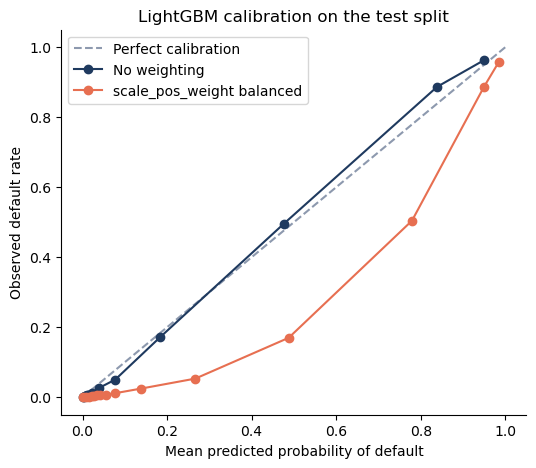

In [13]:
fig, ax = plt.subplots(figsize=(6, 5))
ax.plot([0, 1], [0, 1], linestyle="--", color=P["grey"], label="Perfect calibration")
for p, label, colour in [(test_probs["LightGBM"], "No weighting", P["navy"]),
                         (p_lgbm_weighted, "scale_pos_weight balanced", P["red"])]:
    frac, mean_pred = calibration_curve(y_test, p, n_bins=15, strategy="quantile")
    ax.plot(mean_pred, frac, marker="o", color=colour, label=label)
ax.set_xlabel("Mean predicted probability of default")
ax.set_ylabel("Observed default rate")
ax.set_title("LightGBM calibration on the test split")
ax.legend()
save_fig(fig, "fig04_class_weight_calibration.png")
plt.show()

Weighting the defaults leaves the ranking almost unchanged (CV ROC-AUC 0.9750 against 0.9748, CV PR-AUC 0.9052 against 0.9081) but distorts the probabilities. The weighted model predicts a mean probability of default of 25.9% on the test split, where 17.6% of loans actually default, and its Brier score worsens from 0.0412 to 0.0582; its calibration curve lies below the diagonal, meaning that its predicted probabilities are higher than the default rates observed. Weighting mainly moves loans across a fixed threshold of 0.5 (recall at 0.5 rises from 0.81 to 0.93), but we do not use 0.5: notebook 05 chooses the threshold on the probability scale from the cost matrix, and the expected value of a loan needs a probability that means what it says. We therefore train LightGBM without class weights and handle the imbalance through the threshold and the cost matrix. The logistic regression keeps `class_weight="balanced"` as the brief specifies; its threshold is chosen in the same cost-based way, so the weighting does not bias the policy comparison in notebook 05.

## 8. Comparison of the five models

The table collects the cross-validation results (mean and standard deviation of ROC-AUC and PR-AUC, and the mean fit time per fold) and the test-split scores of every model. It is saved to `docs/model_comparison.csv` so the report and the app quote the same numbers. Recall, precision and F1 at a threshold of 0.5 are a common reference only; the business threshold is set in notebook 05.

In [14]:
comparison = pd.DataFrame(comparison_rows)
comparison["feature_set"] = "deployment"
comparison["cv_data"] = np.where(comparison["model"] == "Random forest", "200,000-loan stratified subsample",
                                 "full training split")
comparison_cols = ["model", "cv_data", "cv_roc_auc_mean", "cv_roc_auc_std", "cv_pr_auc_mean", "cv_pr_auc_std",
                   "fit_seconds_per_fold", "full_fit_seconds", "test_roc_auc", "test_pr_auc", "test_brier",
                   "test_recall_at_0.5", "test_precision_at_0.5", "test_f1_at_0.5"]
comparison = comparison[comparison_cols]
comparison.round(5).to_csv(config.DOCS_DIR / "model_comparison.csv", index=False)
print("Saved docs/model_comparison.csv")
comparison.round(4)

Saved docs/model_comparison.csv


,model,cv_data,cv_roc_auc_mean,cv_roc_auc_std,cv_pr_auc_mean,cv_pr_auc_std,fit_seconds_per_fold,full_fit_seconds,test_roc_auc,test_pr_auc,test_brier,test_recall_at_0.5,test_precision_at_0.5,test_f1_at_0.5
0,Dummy (prior),full training split,0.5000,0.0000,0.1756,0.0000,4.7140,4.8992,0.5000,0.1757,0.1448,0.0000,0.0000,0.0000
1,Logistic regression,full training split,0.8634,0.0012,0.6224,0.0045,16.4370,21.4111,0.8655,0.6277,0.1513,0.8195,0.4325,0.5662
2,Random forest,"200,000-loan stratified subsample",0.9551,0.0017,0.8621,0.0033,30.1511,34.7700,0.9578,0.8655,0.0560,0.6790,0.8898,0.7703
3,Hist gradient boosting,full training split,0.9729,0.0007,0.9062,0.0025,10.2517,13.1520,0.9743,0.9080,0.0411,0.8034,0.8834,0.8415
4,LightGBM,full training split,0.9748,0.0006,0.9081,0.0022,6.7846,7.3051,0.9748,0.9068,0.0412,0.8074,0.8767,0.8406


The bar chart shows the cross-validated ranking with the fold-to-fold spread as error bars.

Saved docs/figures/fig04_cv_model_comparison.png


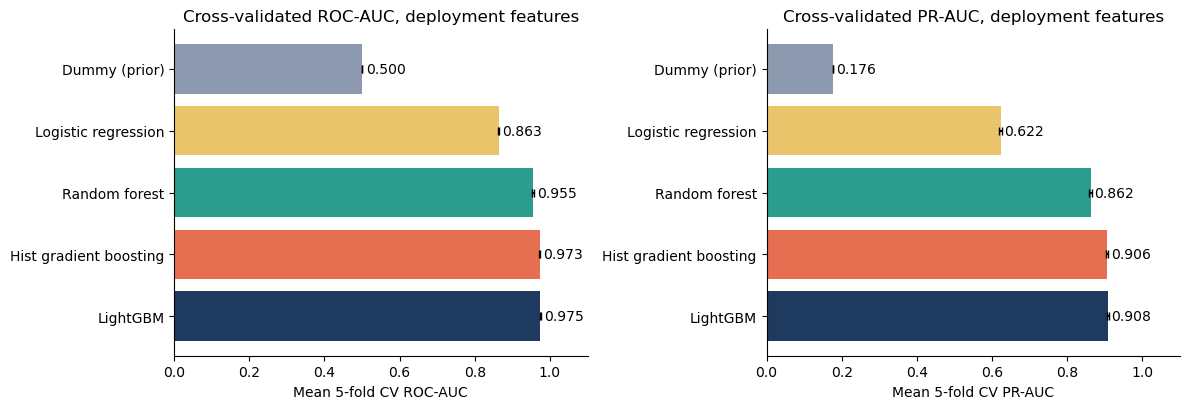

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
names = comparison["model"].tolist()
for ax, metric, title in zip(axes, ["roc_auc", "pr_auc"], ["ROC-AUC", "PR-AUC"]):
    means = comparison[f"cv_{metric}_mean"]
    ax.barh(names, means, xerr=comparison[f"cv_{metric}_std"], color=[MODEL_COLOURS[n] for n in names], capsize=3)
    for i, v in enumerate(means):
        ax.text(v + 0.01, i, f"{v:.3f}", va="center")
    ax.set_xlim(0, 1.1)
    ax.set_xlabel(f"Mean 5-fold CV {title}")
    ax.set_title(f"Cross-validated {title}, deployment features")
    ax.invert_yaxis()
fig.tight_layout()
save_fig(fig, "fig04_cv_model_comparison.png")
plt.show()

The tree ensembles are far ahead of the logistic regression, and the two gradient boosting models are ahead of the forest. LightGBM has the highest cross-validated ROC-AUC (0.9748, sd 0.0006) and PR-AUC (0.9081), with histogram gradient boosting close behind (0.9729 and 0.9062), the random forest at 0.9551 and 0.8621 on its subsample, and the logistic regression at 0.8634 and 0.6224. Every fold standard deviation is below 0.005, so the gaps between models are many times larger than the noise. The test split confirms the ranking with almost identical numbers, which also shows that the cross-validation estimates are not optimistic. The logistic regression's Brier score (0.1513) is worse than the dummy's (0.1448) because balanced weighting raises all its probabilities, not because it ranks loans badly. LightGBM is also the fastest of the real models: 6.8 seconds per fold and 7.3 seconds on the full training split, against 10.3 and 13.2 seconds for histogram gradient boosting and 16.4 and 21.4 seconds for the logistic regression.

## 9. ROC and precision-recall curves on the test split

The curves show the same ranking on the 179,191 test loans across all thresholds. The ROC curve plots the share of defaults caught against the share of good loans wrongly flagged; the precision-recall curve plots the share of flagged loans that really default against the share of defaults caught.

Saved docs/figures/fig04_roc_pr_curves_test.png


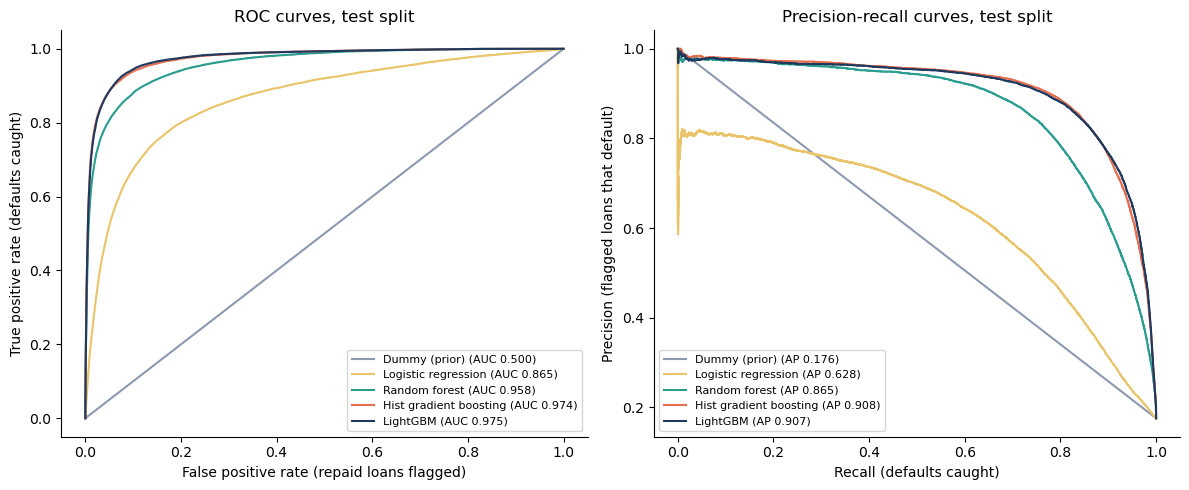

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for name, p in test_probs.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    axes[0].plot(fpr, tpr, color=MODEL_COLOURS[name], label=f"{name} (AUC {roc_auc_score(y_test, p):.3f})")
    prec, rec, _ = precision_recall_curve(y_test, p)
    axes[1].plot(rec, prec, color=MODEL_COLOURS[name], label=f"{name} (AP {average_precision_score(y_test, p):.3f})")
axes[0].set_xlabel("False positive rate (repaid loans flagged)")
axes[0].set_ylabel("True positive rate (defaults caught)")
axes[0].set_title("ROC curves, test split")
axes[1].set_xlabel("Recall (defaults caught)")
axes[1].set_ylabel("Precision (flagged loans that default)")
axes[1].set_title("Precision-recall curves, test split")
for ax in axes:
    ax.legend(loc="lower right" if ax is axes[0] else "lower left", fontsize=8)
fig.tight_layout()
save_fig(fig, "fig04_roc_pr_curves_test.png")
plt.show()

On the test split the LightGBM and histogram gradient boosting curves lie almost on top of each other and above the other models across the whole range, with the random forest just below and the logistic regression clearly below. The precision-recall panel shows the practical difference best: to catch most defaults, the logistic regression has to flag many repaid loans as well (average precision 0.628), while LightGBM keeps precision high until recall is close to 1 (average precision 0.907). For a bank this means fewer good customers turned away for every bad loan avoided.

## 10. Overfitting check and learning curve for LightGBM

A model that fits the training loans much better than unseen loans has memorised noise. We compare LightGBM's ROC-AUC on the training folds with its cross-validated ROC-AUC, and draw a learning curve: the model is trained on growing shares of each training fold (5% to 100%) and scored on the held-out fold. If the two lines are close and the validation line has flattened, more data or a simpler model would change little.

In [17]:
start = time.time()
sizes, train_sc, val_sc = learning_curve(
    md.make_pipeline(lgbm(), DEP_NUM, CAT), X_train, y_train, cv=FOLDS, scoring="roc_auc",
    train_sizes=[0.05, 0.1, 0.25, 0.5, 1.0], n_jobs=1, shuffle=True,
    random_state=config.RANDOM_STATE)
print(f"Learning curve computed in {time.time() - start:.0f} s")
lc = pd.DataFrame({"training_loans": sizes, "train_roc_auc": train_sc.mean(axis=1),
                   "cv_roc_auc": val_sc.mean(axis=1), "cv_roc_auc_std": val_sc.std(axis=1)})
lc["gap"] = lc["train_roc_auc"] - lc["cv_roc_auc"]
lc.round(4)

Learning curve computed in 132 s


,training_loans,train_roc_auc,cv_roc_auc,cv_roc_auc_std,gap
0,28670,0.9855,0.9695,0.0009,0.0160
1,57340,0.9808,0.9719,0.0008,0.0089
2,143352,0.9772,0.9737,0.0004,0.0036
3,286704,0.9763,0.9744,0.0006,0.0019
4,573408,0.9759,0.9748,0.0004,0.0011


The learning curve below plots both lines with the fold spread as a band.

Saved docs/figures/fig04_learning_curve_lightgbm.png


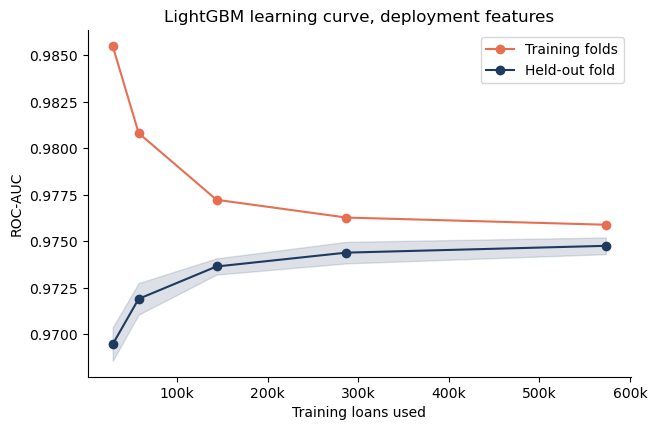

In [18]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(lc["training_loans"], lc["train_roc_auc"], marker="o", color=P["red"], label="Training folds")
ax.plot(lc["training_loans"], lc["cv_roc_auc"], marker="o", color=P["navy"], label="Held-out fold")
ax.fill_between(lc["training_loans"], lc["cv_roc_auc"] - lc["cv_roc_auc_std"],
                lc["cv_roc_auc"] + lc["cv_roc_auc_std"], color=P["navy"], alpha=0.15)
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v / 1000:,.0f}k"))
ax.set_xlabel("Training loans used")
ax.set_ylabel("ROC-AUC")
ax.set_title("LightGBM learning curve, deployment features")
ax.legend()
save_fig(fig, "fig04_learning_curve_lightgbm.png")
plt.show()

LightGBM does not overfit in a way that matters. With the full training folds its ROC-AUC is 0.9759 on the data it was trained on and 0.9748 on the held-out fold, a gap of 0.0011, and the cross-validated train score in section 6.5 tells the same story (0.9760 against 0.9748). The learning curve shows the gap closing from 0.016 at 28,670 loans to 0.001 at 573,408, while the held-out score rises from 0.9695 and flattens above about 290,000 loans (0.9744 at 286,704 and 0.9748 at 573,408). More data of the same kind would add little, so further gains have to come from tuning (notebook 05) or from new information about the borrower, not from more loans.

## 11. Choice of model

**We choose LightGBM** as the model to tune and deploy, and keep the logistic regression as the interpretable comparison model.

*Technical reasons.* LightGBM has the highest cross-validated ROC-AUC and PR-AUC on identical folds, and the test split reproduces the ranking. Its probabilities are well calibrated without class weighting (mean predicted probability 0.1765 against an observed rate of 0.1757 on the test split), it shows almost no gap between training and validation scores, and it fits in seconds, which leaves room for the 75 fits of the randomised search in notebook 05. Histogram gradient boosting is almost as accurate, but it is slower and has fewer regularisation settings to tune; the random forest is less accurate and its file size grows quickly with the data, which matters for the app.

*Business reasons.* A bank needs three things from the model: to rank applications well, so that declining the riskiest few per cent removes most of the losses; to give probabilities it can multiply by money; and to explain each decision to a credit officer and, if needed, to the applicant. LightGBM ranks best, its calibrated probabilities feed the expected value directly, and SHAP gives an exact explanation of each score in terms of the 23 inputs because the tree preprocessor keeps one column per feature. Its model file is small and it scores a single loan in milliseconds, which supports SMART objective 3 (a scored decision with an explanation in under 3 seconds).

*Why keep the logistic regression.* With a test ROC-AUC of 0.8655 it already meets the 0.80 of SMART objective 1, and its coefficients and permutation importance give a transparent check on what the more complex model does. If a regulator or credit committee asks for a simpler scorecard, it is the fall-back, and notebook 05 compares its business value with LightGBM's.

## 12. Summary and run time

The last cell prints the total run time of the notebook, which we keep under 25 minutes on the team's 8-thread laptop.

In [19]:
print(f"Notebook 04 ran in {(time.time() - NOTEBOOK_START) / 60:.1f} minutes")

Notebook 04 ran in 13.9 minutes


**Summary.** We framed CreditLens as a binary classification problem judged by ranking (ROC-AUC, PR-AUC), calibration (Brier score) and money (net value from the cost matrix). We removed `ApprovalYear`, `ApprovalMonth` and `DisbursementLagDays` from the deployed model because they cannot be valued for a new application and partly encode right-censoring, at a cost of 0.005 in CV ROC-AUC (0.9801 to 0.9748), and kept `Recession` as a scenario input. Without `TermYears` and `RealEstate` the CV ROC-AUC falls to 0.838, so term carries most of the signal; it is kept because it is agreed at approval, with the caveat recorded for the model card. On identical folds of the deployment feature set LightGBM (CV ROC-AUC 0.9748, PR-AUC 0.9081) beat histogram gradient boosting (0.9729), the random forest (0.9551 on a 200,000-loan subsample), the logistic regression (0.8634) and the dummy baseline (0.5000). Class weighting did not improve ranking and spoiled calibration, so LightGBM is trained without weights. The learning curve shows a train-validation gap of 0.001 on the full folds. Notebook 05 tunes LightGBM, chooses the business threshold and evaluates the final model.